# Grid Search: Hyperparameter-Optimierung für Entscheidungsbäume

In diesem Notebook wird **Grid Search** für einen Entscheidungsbaum umgesetzt
(Studienbrief 4, Kap. 2.1). Ziel ist es, die Hyperparameterkombination zu
finden, mit der der Baum handgeschriebene Ziffern am besten klassifiziert.

- Teil 1: Datengrundlage
- Teil 2: Grid Search wie im Studienbrief (Algorithmus 2.1–2.4)
- Teil 3: Problem *Data Leakage* und saubere Variante mit Validierung
- Teil 4: Übungsaufgaben

## Teil 1: Datengrundlage

Verwendet wird der Datensatz `digits` aus scikit-learn (`load_digits()`).
Er ist eine Version des Datensatzes *Optical Recognition of Handwritten
Digits* aus dem UCI Machine Learning Repository [@alpaydin1998].

- handgeschriebene Ziffern 0–9, d.h. Klassifikation mit $K = 10$ Klassen
- jede Ziffer als Bild mit $8 \times 8$ Pixeln, d.h. $p = 64$ Attribute
- Pixelwerte zwischen 0 (weiß) und 16 (schwarz)
- 1797 Beobachtungen, keine fehlenden Werte
- kein vorgegebener Train/Test-Split, die Aufteilung erfolgt zufällig

Hinweis: Im Studienbrief wird der Datensatz als „Pen-Based Recognition of
Handwritten Digits“ beschrieben (16 Attribute, 10992 Beobachtungen). Das ist
ein anderer Datensatz desselben Projekts; der Code verwendet tatsächlich die
hier beschriebenen Optical Digits.

In [1]:
from sklearn.datasets import load_digits

digits = load_digits()
print("Datenmatrix X:", digits.data.shape)
print("Zielvariable y:", digits.target.shape)
print("Wertebereich der Pixel:", digits.data.min(), "bis", digits.data.max())
print("Klassen:", sorted(set(digits.target.tolist())))

Datenmatrix X: (1797, 64)
Zielvariable y: (1797,)
Wertebereich der Pixel: 0.0 bis 16.0
Klassen: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


Einige Beispiele: jede Zeile der Datenmatrix ist ein $8 \times 8$-Bild,
das zeilenweise zu einem Vektor mit 64 Einträgen ausgerollt wurde.

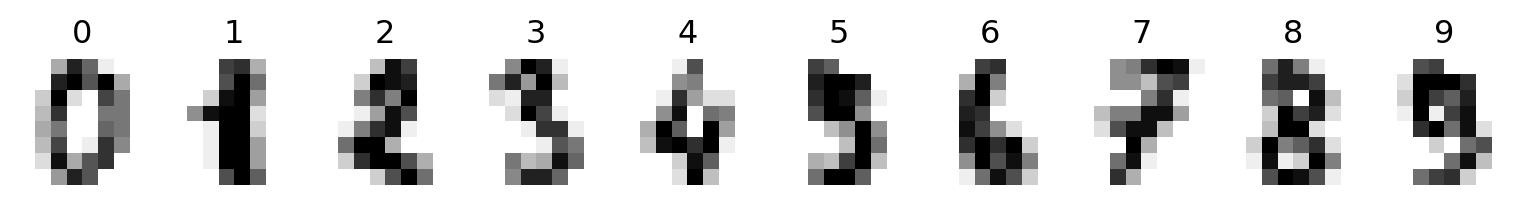

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 10, figsize=(10, 1.6))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.show()

## Teil 2: Grid Search wie im Studienbrief

Der Code folgt Algorithmus 2.1–2.4 aus dem Studienbrief, mit drei kleinen
Korrekturen:

- `print(test)` am Ende würde einen Fehler auslösen (`test` existiert nicht),
  ausgegeben wird stattdessen das Ergebnis
- neben der besten Accuracy wird auch die beste **Kombination** gemerkt
  (das verlangt Übungsaufgabe 2.2)
- die Schleifenvariablen heißen `depth` und `min_split` statt `max` und
  `min`, da `max` und `min` eingebaute Python-Funktionen überdecken

Zusätzlich ist `random_state` gesetzt, damit die Ergebnisse reproduzierbar
sind (Algorithmus 2.4).

### Teil I: Importe (Algorithmus 2.1)

In [3]:
from sklearn import tree
from sklearn.model_selection import train_test_split

### Teil II: Grid Search (Algorithmus 2.2 und 2.4)

Drei verschachtelte Schleifen durchlaufen alle Kombinationen der drei
Hyperparameter. Für jede Kombination wird ein Baum trainiert und seine
Accuracy auf den Testdaten berechnet.

In [4]:
def main():
    best = 0
    best_params = None
    for crit in c:
        for depth in range(1, 11):
            for min_split in range(2, 11):
                clf = tree.DecisionTreeClassifier(
                    criterion=crit, max_depth=depth,
                    min_samples_split=min_split, random_state=123
                )
                clf = clf.fit(X, y)
                score = clf.score(X_test, y_test)
                if score > best:
                    best = score
                    best_params = (crit, depth, min_split)
    print(f"beste Accuracy: {best:.3f}")
    print(f"beste Kombination (criterion, max_depth, min_samples_split): "
          f"{best_params}")
    return best, best_params

### Teil III: Daten laden, Suchraum festlegen, Grid Search starten (Algorithmus 2.3)

Im Studienbrief enthält `c` zusätzlich `'log_loss'`. In scikit-learn ist
`log_loss` für Entscheidungsbäume aber identisch mit `entropy`; die Option
würde den Suchraum nur verdoppeln, ohne neue Bäume zu erzeugen.

In [5]:
digits = load_digits()
c = ["gini", "entropy"]
X, X_test, y, y_test = train_test_split(
    digits.data, digits.target, test_size=0.2, random_state=0
)
best, best_params = main()

beste Accuracy: 0.867
beste Kombination (criterion, max_depth, min_samples_split): ('gini', 10, 2)


Der Studienbrief nennt eine Accuracy von etwa 88 %. Je nach Zufallsaufteilung
liegt das Ergebnis ungefähr zwischen 86 % und 91 % (ausprobieren: anderer
`random_state` in `train_test_split`).

## Teil 3: Problem *Data Leakage* und saubere Variante

Im Code oben werden die Hyperparameter anhand der **Testdaten** ausgewählt:
von 180 Kombinationen wird die mit der besten Test-Accuracy behalten. Damit
fließen die Testdaten in die Modellwahl ein (*Data Leakage*), und die
gemeldete Accuracy ist zu optimistisch. Die Testdaten sollen aber gerade
schätzen, wie gut das Modell auf **ungesehenen** Daten ist.

Sauberes Vorgehen:

1. Daten in Trainings- und Testdaten teilen; die Testdaten bis zum Schluss
   nicht anfassen
2. Hyperparameter nur mit den Trainingsdaten auswählen, z.B. mit
   Validierungsdaten oder Kreuzvalidierung
3. Das gewählte Modell auf allen Trainingsdaten trainieren und **einmal** auf
   den Testdaten bewerten

### Variante A: Validierungsdaten

Aus den Trainingsdaten werden zusätzlich Validierungsdaten abgespalten
(hier 25 % der Trainingsdaten, also insgesamt 60/20/20). Die Schleifen sind
dieselben wie oben, bewertet wird aber auf den Validierungsdaten.

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=0
)

best, best_params = 0, None
for crit in c:
    for depth in range(1, 11):
        for min_split in range(2, 11):
            clf = tree.DecisionTreeClassifier(
                criterion=crit, max_depth=depth,
                min_samples_split=min_split, random_state=123
            )
            clf.fit(X_train, y_train)
            score = clf.score(X_val, y_val)
            if score > best:
                best, best_params = score, (crit, depth, min_split)

print(f"beste Validierungs-Accuracy: {best:.3f}, Kombination: {best_params}")

crit, depth, min_split = best_params
final = tree.DecisionTreeClassifier(
    criterion=crit, max_depth=depth, min_samples_split=min_split,
    random_state=123
).fit(X, y)
print(f"Test-Accuracy des gewählten Modells: {final.score(X_test, y_test):.3f}")

beste Validierungs-Accuracy: 0.850, Kombination: ('entropy', 9, 6)
Test-Accuracy des gewählten Modells: 0.828


### Variante B: Kreuzvalidierung mit `GridSearchCV`

`GridSearchCV` erledigt die Schleifen und die Kreuzvalidierung in einem
Schritt: die Trainingsdaten werden in 5 Teile geteilt, jede Kombination wird
fünfmal trainiert (jeweils auf 4 Teilen) und auf dem fünften Teil bewertet.
Anschließend wird das beste Modell automatisch auf allen Trainingsdaten neu
trainiert.

In [7]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": list(range(1, 11)),
    "min_samples_split": list(range(2, 11)),
}
search = GridSearchCV(
    tree.DecisionTreeClassifier(random_state=123), param_grid, cv=5
)
search.fit(X, y)

print(f"beste Kreuzvalidierungs-Accuracy: {search.best_score_:.3f}")
print(f"beste Kombination: {search.best_params_}")
print(f"Test-Accuracy des gewählten Modells: {search.score(X_test, y_test):.3f}")

beste Kreuzvalidierungs-Accuracy: 0.852
beste Kombination: {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 3}
Test-Accuracy des gewählten Modells: 0.844


Die Test-Accuracy der sauberen Varianten ist eine ehrliche Schätzung der
Güte auf neuen Daten. Sie liegt typischerweise etwas unter dem Wert aus
Teil 2, weil dort die beste von vielen Test-Accuracies ausgewählt wurde.

## Teil 4: Übungsaufgaben

**2.1) Erweiterter Grid Search.** Vergrößern Sie den Suchraum, indem Sie die
mögliche maximale Tiefe und die Mindestanzahl von Dateneinträgen für einen
Split erhöhen. Passen Sie hierzu das jeweils zweite Argument der
`range()`-Funktion an. Was beobachten Sie (Laufzeit, Accuracy)?

**2.2) Ergebnis Grid Search.** Führen Sie den Code aus und lassen Sie sich die
beste Hyperparameterkombination ausgeben. Wie stark variiert das Ergebnis,
wenn Sie den `random_state` in `train_test_split` ändern?

**2.3) Data Leakage.** Vergleichen Sie die Accuracy aus Teil 2 mit der
Test-Accuracy aus Teil 3. Warum ist der Wert aus Teil 2 zu optimistisch?
Werden in beiden Fällen dieselben Hyperparameter gewählt?